In [1]:
%pip install numpy
%pip install matplotlib
%pip install pandas
%pip install scipy
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
file_path_D1 = r"Pruebas_DELFT_20260929.txt"
file_path_D2 = r"Pruebas_DELFT_20261002.txt"

columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]

def load_gps(file_path):
    gps = pd.read_csv(
        file_path,
        sep=r"\s+",
        skiprows=1,          # skip the descriptive header
        names=columns,
        dtype={
            "point_id": "string",
            "date": "string",
            "time": "string",
            "easting": "float64",
            "northing": "float64",
            "ellipsoidal_height": "float64",
            "geoid_separation": "float64",
            "cq_3d": "float64",
        },
    )

    gps["datetime"] = pd.to_datetime(
        gps["date"] + " " + gps["time"],
        format="%m/%d/%Y %H:%M:%S",
    )
    gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)
    gps = gps.drop(columns=["date", "time"])

    # Determining actual elevations
    gps["elevation"] = gps["ellipsoidal_height"] - gps["geoid_separation"]
    return gps

gps_D1 = load_gps(file_path_D1)
gps_D2 = load_gps(file_path_D2)


display(gps_D1.head())
display(gps_D2.head())

,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,GPS0001,806688.1680,2.343461e+06,-15.2602,-13.9310,0.0159,2026-09-29 11:18:19,-1.3292
1,GPS0002,806687.4266,2.343459e+06,-15.2558,-13.9309,0.0159,2026-09-29 11:18:40,-1.3249
2,GPS0003,806697.2479,2.343461e+06,-15.3033,-13.9310,0.0177,2026-09-29 11:19:18,-1.3723
3,GPS0004,806687.4149,2.343452e+06,-15.3480,-13.9308,0.0156,2026-09-29 11:19:56,-1.4172
4,GPS0005,806680.4073,2.343383e+06,-14.3263,-13.9294,0.0210,2026-09-29 11:22:42,-0.3969


,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,RTCM-Ref0017,806520.1897,2.343199e+06,-2.3498,-13.9267,NaN,2026-10-02 09:52:57,11.5769
1,GPS_Auto_000001,806503.2658,2.343120e+06,-14.1150,-13.9252,0.0171,2026-10-02 09:54:30,-0.1898
2,GPS_Auto_000002,806503.4395,2.343120e+06,-14.1546,-13.9252,0.0157,2026-10-02 09:54:31,-0.2294
3,GPS_Auto_000003,806503.7183,2.343120e+06,-14.0603,-13.9252,0.0158,2026-10-02 09:54:32,-0.1351
4,GPS_Auto_000004,806504.1683,2.343120e+06,-14.0468,-13.9252,0.0155,2026-10-02 09:54:33,-0.1216


In [3]:
def add_trajectory_and_speed(gps):
    gps = gps.copy()

        # Extract the label from point_id ("GPS_Auto_000001" -> "GPS_Auto", "GPS0001" -> "GPS")
    gps["trajectory"] = gps["point_id"].str.extract(
        r"^([A-Za-z]+(?:_[A-Za-z]+)*)",
        expand=False,
    )
    # Day 2 calls the boat track GPS_Auto; give it the same label as day 1
    gps["trajectory"] = gps["trajectory"].replace({"GPS_Auto": "TEST"})

    # Calculate horizontal speed within each trajectory
    ordered_gps = gps.sort_values(["trajectory", "datetime"])

    delta_easting = ordered_gps.groupby("trajectory")["easting"].diff()
    delta_northing = ordered_gps.groupby("trajectory")["northing"].diff()

    delta_time = (
        ordered_gps.groupby("trajectory")["datetime"]
        .diff()
        .dt.total_seconds()
    )

    distance = np.hypot(delta_easting, delta_northing)

    # Speed in metres per second
    speed_m_s = distance / delta_time.where(delta_time > 0)

    # Add the results to the original DataFrame order
    gps["speed_m_s"] = speed_m_s.reindex(gps.index)
    gps["speed_km_h"] = gps["speed_m_s"] * 3.6
    return gps


gps_D1 = add_trajectory_and_speed(gps_D1)
gps_D2 = add_trajectory_and_speed(gps_D2)

test_D1 = gps_D1[gps_D1["trajectory"] == "TEST"].sort_values("datetime")
test_D2 = gps_D2[gps_D2["trajectory"] == "TEST"].sort_values("datetime")

gps_points_D1 = gps_D1[gps_D1["trajectory"] == "GPS"].sort_values("datetime")
gps_points_D2 = gps_D2[gps_D2["trajectory"] == "GPS"].sort_values("datetime")

show = ["point_id", "trajectory", "datetime", "speed_m_s", "speed_km_h"]
display(gps_D1[show])
display(gps_D2[show])

# Both days in one table: the functions select the right day by date and time
gps = pd.concat([gps_D1, gps_D2], ignore_index=True)
gps_points = pd.concat([gps_points_D1, gps_points_D2], ignore_index=True)

,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,GPS0001,GPS,2026-09-29 11:18:19,NaN,NaN
1,GPS0002,GPS,2026-09-29 11:18:40,0.074992,0.269972
2,GPS0003,GPS,2026-09-29 11:19:18,0.264426,0.951933
3,GPS0004,GPS,2026-09-29 11:19:56,0.362235,1.304045
4,GPS0005,GPS,2026-09-29 11:22:42,0.417235,1.502046
...,...,...,...,...,...
12898,TEST012676,TEST,2026-09-29 11:09:01,0.618595,2.226943
12899,TEST012677,TEST,2026-09-29 11:09:02,0.770201,2.772725
12900,TEST012678,TEST,2026-09-29 11:09:03,0.628138,2.261297
12901,TEST012679,TEST,2026-09-29 11:09:04,0.256624,0.923846


,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,RTCM-Ref0017,RTCM,2026-10-02 09:52:57,NaN,NaN
1,GPS_Auto_000001,TEST,2026-10-02 09:54:30,NaN,NaN
2,GPS_Auto_000002,TEST,2026-10-02 09:54:31,0.328568,1.182845
3,GPS_Auto_000003,TEST,2026-10-02 09:54:32,0.368721,1.327395
4,GPS_Auto_000004,TEST,2026-10-02 09:54:33,0.475849,1.713056
...,...,...,...,...,...
6143,GPS0001,GPS,2026-10-02 11:43:30,NaN,NaN
6144,GPS0002,GPS,2026-10-02 11:44:11,0.021656,0.077960
6145,GPS0003,GPS,2026-10-02 11:44:36,0.018149,0.065336
6146,GPS0004,GPS,2026-10-02 11:45:17,0.076163,0.274187


In [4]:
cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

df_SSC01 = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)
df_SSC02L = pd.read_csv("SSC02A.dat", sep=r"\s+", header=None, names=cols)
df_SSC02H = pd.read_csv("SSC02B.dat", sep=r"\s+", header=None, names=cols)

In [5]:
df_SSC01["t"] = df_SSC01.index / 16                     #Data from first field compain on 29 september
start = pd.Timestamp("2026-09-29 06:00:00")
df_SSC01["time"] = start + pd.to_timedelta(df_SSC01["t"], unit="s")

df_SSC02L["t"] = df_SSC02L.index / 16.                  #Data from second field compain on 2 oktober from the lowest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02L["time"] = start + pd.to_timedelta(df_SSC02L["t"], unit="s")

df_SSC02H["t"] = df_SSC02H.index / 16                   #Data from second field compain on 2 oktober from the highest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02H["time"] = start + pd.to_timedelta(df_SSC02H["t"], unit="s")

In [6]:
m = pd.read_csv("manoeuvresTimes.csv") #import of the manoeuvres times
manoeuvres = {k: v.split(";") for k, v in zip(m["id"], m["times"])}

# Both days in one table: the functions select the right day by date and time
gps = pd.concat([gps_D1, gps_D2], ignore_index=True)
gps_points = pd.concat([gps_points_D1, gps_points_D2], ignore_index=True)

# How each GPS point is drawn on the map: colour, marker shape, size (s) and legend name
GPS_STYLE = {
    "GPS0001": dict(color="black",  marker="^", label="Flag"),
    "GPS0002": dict(color="black",  marker="^", label="Flag"),
    "GPS0003": dict(color="purple", marker="*", s=220, label="Sensor"),
    "GPS0004": dict(color="black",  marker="^", label="Flag"),
}
GPS_DEFAULT = dict(color="0.6", marker="x", s=90, label="GPS point")   # any point not listed above

def select(ids):
    """Accepts one id ("B-11"), a list (["B-11", "B-12"]) or a whole type ("B")."""
    if isinstance(ids, str):
        ids = [ids]
    out = []
    for i in ids:
        if i in manoeuvres:
            out.append(i)
        else:
            matches = [k for k in manoeuvres if k.split("-")[0] == i]
            if not matches:
                raise KeyError(f"Unknown manoeuvre or type: {i}")
            out += matches
    return out

def sources(name, sensor="Both"):
    """Which dataframe(s) to use for a manoeuvre, from its series digit (the 3 in B-31)."""
    if name[-2] in "1234":
        return [(df_SSC01, "", "-")]
    out = []
    if sensor in ("Both", "Low"):
        out.append((df_SSC02L, "Low", "-."))
    if sensor in ("Both", "High"):
        out.append((df_SSC02H, "High", "--"))
    return out

def plot_track(ax, name, c, passes, before, after, norm, colour):
    """GPS track of the boat around one manoeuvre. c is the time of the first pass."""
    start = c - pd.Timedelta(seconds=before)
    end = c + pd.Timedelta(seconds=passes[-1] + after)

    test = gps[gps["datetime"].between(start, end) & (gps["trajectory"] == "TEST")].sort_values("datetime")
    if test.empty:
        print(f"No GPS track around {name} ({c:%Y-%m-%d %H:%M:%S}), not on the map")
        return [], []
    rel_t = (test["datetime"] - c).dt.total_seconds()
    ax.plot(test["easting"], test["northing"], color=colour, lw=1, label=name)
    ax.scatter(test["easting"], test["northing"], c=rel_t, cmap="viridis", norm=norm, s=15, zorder=3)

    # Position of the boat at the moment of each pass, interpolated along the track.
    inside = [p for p in passes if rel_t.min() <= p <= rel_t.max()]
    x, y = np.interp(inside, rel_t, test["easting"]), np.interp(inside, rel_t, test["northing"])
    ax.scatter(x, y, color="red", marker="x", s=100, linewidths=2, zorder=5)
    if inside:                              # name next to the first pass
        ax.annotate(name, (x[0], y[0]), xytext=(8, 8), textcoords="offset points", fontweight="bold")

    # GPS points measured during this manoeuvre get the colour of their time.
    if "gps_points" in globals():
        pts = gps_points[gps_points["datetime"].between(start, end)]
        ax.scatter(pts["easting"], pts["northing"], c=(pts["datetime"] - c).dt.total_seconds(),
                   cmap="viridis", norm=norm, marker="x", s=70, linewidths=1.5, zorder=4)
    return list(x), list(y)                 # where the boat was at each pass

def plot_overlay(ids, sensor="Both", before=120, after=120, col="analog1", show_map=True, zoom=None):
    show_map = show_map and "gps" in globals()      # no map if the GPS data is not loaded
    if show_map:
        fig, (ax, ax_map) = plt.subplots(1, 2, figsize=(18, 6), layout="constrained",
                                         gridspec_kw={"width_ratios": [1.2, 1]})
        norm = mpl.colors.Normalize(-before, after)  # colour scale of the map: seconds from passage
    else:
        fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    days = set()                            # days that appear in this plot
    pass_x, pass_y = [], []                 # where the boat was at each passage

    for name in select(ids):
        t = manoeuvres[name]
        if isinstance(t, str):              # single pass -> list of one
            t = [t]
        offsets = pd.to_timedelta(t)        # time of day of each pass
        passes = [(off - offsets[0]).total_seconds() for off in offsets]   # seconds after the first pass
        colour = None

        for data, suffix, ls in sources(name, sensor):
            times = data["time"].iloc[0].normalize() + offsets
            c = times[0]
            win = data[(data["time"] >= c - pd.Timedelta(seconds=before)) &
                       (data["time"] <= times[-1] + pd.Timedelta(seconds=after))]
            if win.empty:
                print(f"No data around {name}{suffix} ({c:%H:%M:%S}), skipped")
                continue
            rel_t = (win["time"] - c).dt.total_seconds()
            line, = ax.plot(rel_t, win[col], ls=ls, lw=0.8, label=f"{name}{suffix}  ({c:%H:%M:%S})")
            colour = colour or line.get_color()

        if len(t) > 1:                      # F manoeuvres: mark every pass
            for i, x in enumerate(passes, 1):
                ax.axvline(x, color="k", ls="--", lw=0.8)
                ax.text(x, 0.95, f"pass {i}", transform=ax.get_xaxis_transform(),
                        ha="center", fontsize=10, color="red",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="k"))

        if show_map:                        # same manoeuvre on the map, in the same colour
            day = sources(name)[0][0]["time"].iloc[0].normalize()
            days.add(day)
            norm.vmax = max(norm.vmax, passes[-1] + after)
            x, y = plot_track(ax_map, name, day + offsets[0], passes, before, after, norm, colour)
            pass_x += x
            pass_y += y

    ax.axvline(0, color="k", ls="--", lw=0.8)
    ax.set_xlabel("Time relative to boat passage (s)")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: {before} s before to {after} s after passage")
    ax.grid(True, alpha=0.3)
    ax.legend()

    if show_map:
        centre = None                       # middle of the zoomed map
        if "gps_points" in globals():       # GPS points of the plotted day(s), each in its own style
            ref = gps_points[gps_points["datetime"].dt.normalize().isin(list(days))]
            in_legend = set()
            for pid, e, n in zip(ref["point_id"], ref["easting"], ref["northing"]):
                style = dict(GPS_DEFAULT, **GPS_STYLE.get(pid, {}))
                label = style.pop("label")
                ax_map.scatter(e, n, linewidths=1.5, zorder=6,
                               label=None if label in in_legend else label, **style)
                in_legend.add(label)
            if not ref.empty:               # median: one far-away point does not pull the map aside
                centre = ref["easting"].median(), ref["northing"].median()
        
        if centre is None and pass_x:       # no GPS points: use the boat passages instead
            centre = np.mean(pass_x), np.mean(pass_y)
        ax_map.scatter([], [], color="red", marker="x", s=100, linewidths=2, label="Boat at passage")
        ax_map.set_aspect("equal", adjustable="datalim")
        if zoom and centre:                 # show only zoom metres around the GPS points
            ax_map.set_aspect("equal", adjustable="box")
            ax_map.set_xlim(centre[0] - zoom, centre[0] + zoom)
            ax_map.set_ylim(centre[1] - zoom, centre[1] + zoom)
        ax_map.set_xlabel("Easting [m]")
        ax_map.set_ylabel("Northing [m]")
        ax_map.set_title("GPS track of the boat")
        ax_map.grid(True, alpha=0.3)
        ax_map.legend()
        fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax_map,
                     label="Time relative to boat passage (s)")

    plt.show()

#### Plotting manoeuvres with `plot_overlay`
`plot_overlay` plots the sensor signal around one or more boat passages, with time shown relative to the moment of passage. Next to it, the GPS track of the boat over the same period is shown on a map.

```python
plot_overlay("B-21", before=120, after=120, col="w")   # one manoeuvre
plot_overlay(["B-11", "B-12"], col="analog1")          # a few manoeuvres
plot_overlay("B", col="analog1")                       # every B manoeuvre
```
| Argument | What it does | Default |
|---|---|---|
| `before` | Seconds to plot before the manoeuvre | `120` |
| `after` | Seconds to plot after the manoeuvre | `120` |
| `col` | Column to plot, e.g. `"analog1"`, `"u"`, `"v"`, `"w"`, `"pressure"` | `"analog1"` |
| `sensor` | Which sensor to use for the second field day (see below) | `"Both"` |
| `show_map` | Show the GPS map next to the plot | `True` |


The `sensor` option only applies to data from the second field day (2 October).
- `sensor="Both"` → plots both the high and the low sensor
- `sensor="Low"` → plots only the low sensor
- `sensor="High"` → plots only the high sensor

In [7]:
# before = 240
# after = 240
# col = "analog1"

# # Select all available B1, B2, B3 and B4 manoeuvres
# ids = [
#     name for name in manoeuvres
#     if name.startswith(("B1-", "B2-", "B3-", "B4-"))
# ]

# ids = sorted(
#     (
#         name for name in manoeuvres
#         if name.startswith(("B1-", "B2-", "B3-", "B4-"))
#     ),
#     key=lambda name: tuple(
#         int(part) for part in name[1:].split("-")
#     ),
# )

# # Common colour scale for all GPS plots
# max_pass = max(
#     (
#         pd.to_timedelta(manoeuvres[name]) - pd.to_timedelta(manoeuvres[name])[0]
#     ).total_seconds().max()
#     for name in ids
# )

# norm = mpl.colors.Normalize(-before, max_pass + after)

# fig, axes = plt.subplots(
#     len(ids), 2,
#     figsize=(18, 5 * len(ids)),
#     squeeze=False,
#     layout="constrained",
#     gridspec_kw={"width_ratios": [1.2, 1]},
# )

# for row, name in enumerate(ids):
#     ax = axes[row, 0]
#     ax_map = axes[row, 1]

#     t = manoeuvres[name]
#     offsets = pd.to_timedelta(t)
#     passes = [
#         (offset - offsets[0]).total_seconds()
#         for offset in offsets
#     ]

#     colour = None

#     for data, suffix, ls in sources(name):
#         times = data["time"].iloc[0].normalize() + offsets
#         c = times[0]

#         win = data[
#             (data["time"] >= c - pd.Timedelta(seconds=before))
#             & (data["time"] <= times[-1] + pd.Timedelta(seconds=after))
#         ]

#         if win.empty:
#             continue

#         rel_t = (win["time"] - c).dt.total_seconds()

#         line, = ax.plot(
#             rel_t,
#             win[col],
#             ls=ls,
#             lw=0.8,
#             label=f"{name}{suffix} ({c:%H:%M:%S})",
#         )

#         if colour is None:
#             colour = line.get_color()

#     for x in passes:
#         ax.axvline(x, color="k", ls="--", lw=0.8)

#     ax.axvline(0, color="k", ls="--", lw=0.8)
#     ax.set_title(f"{name}: {col}")
#     ax.set_ylabel(col)
#     ax.grid(True, alpha=0.3)
#     ax.legend()

#     # GPS plot
#     day = sources(name)[0][0]["time"].iloc[0].normalize()
#     plot_track(
#         ax_map,
#         name,
#         day + offsets[0],
#         passes,
#         before,
#         after,
#         norm,
#         colour,
#     )

#     ax_map.scatter(
#         gps_points["easting"],
#         gps_points["northing"],
#         color="0.6",
#         marker="x",
#         s=40,
#         label="GPS points",
#     )

#     ax_map.set_aspect("equal", adjustable="datalim")
#     ax_map.set_xlabel("Easting [m]")
#     ax_map.set_ylabel("Northing [m]")
#     ax_map.set_title(f"{name}: GPS track")
#     ax_map.grid(True, alpha=0.3)
#     ax_map.legend()

# axes[-1, 0].set_xlabel("Time relative to boat passage (s)")

# fig.colorbar(
#     mpl.cm.ScalarMappable(norm=norm, cmap="viridis"),
#     ax=axes[:, 1],
#     label="Time relative to boat passage (s)",
# )

# plt.show()
# # plot_overlay("B-21", before = 240, after = 240, col = "analog1")                            # one manoeuvre

# #plot_overlay(df, "B-21", before = 1000, after = 1000, col = "v")    
# #plot_overlay(df, "B-21", before = 120, after = 120, col = "w")                       # one manoeuvre
#                    # one manoeuvre
# #plot_overlay(df, ["B-11", "B-12"], col="analog")    # a few
# #plot_overlay(df, "B", col="analog1")                 # every B manoeuvre
# #plot_overlay(df, "A1")                         # every A1 manoeuvre

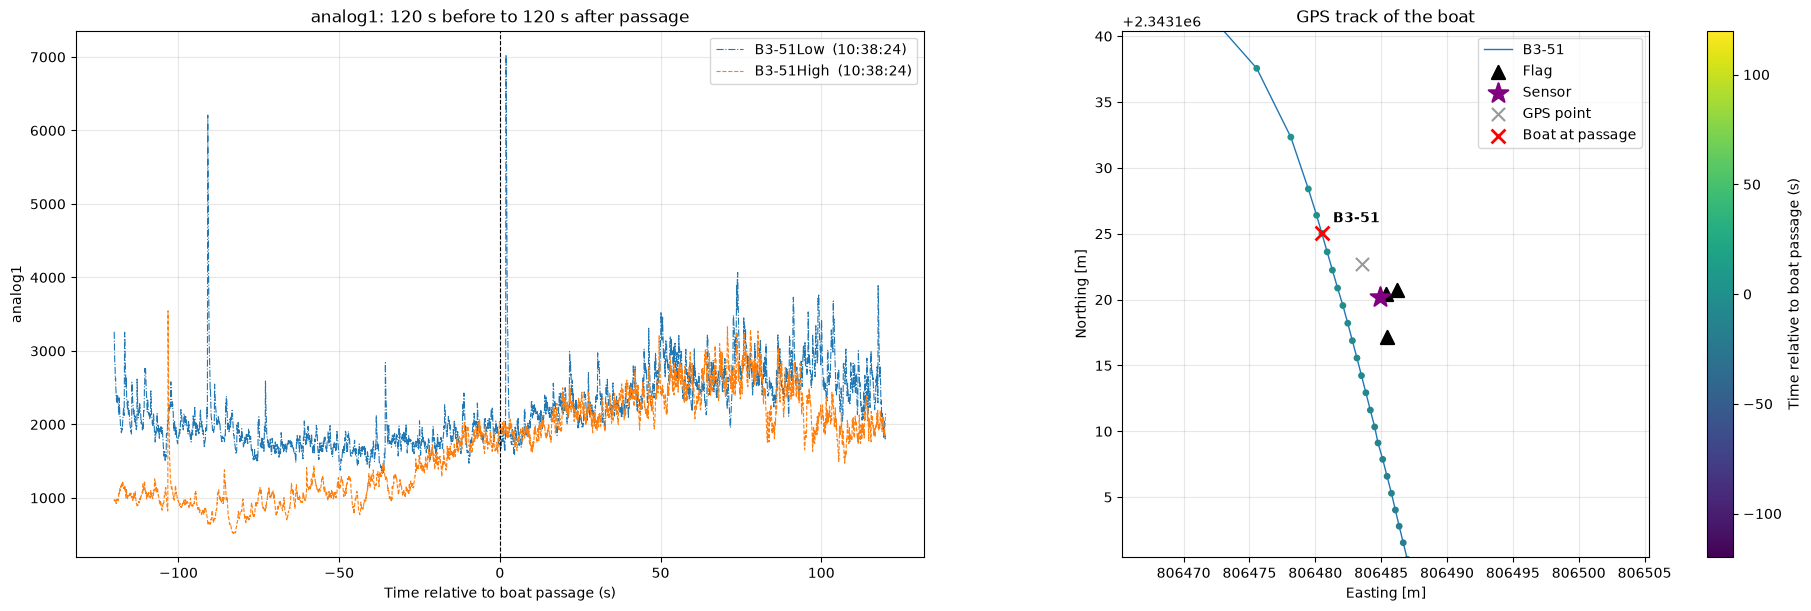

In [8]:
plot_overlay("B3-51", before = 120, after = 120, col = "analog1", zoom=20)